# Facial expression classification

Set DATA_ROOT to the dataset on your machine. Run All displays the existing results. To train or evaluate, enable the corresponding switches below. Use a new RUN_NAME for a fresh experiment.

In [ ]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown, Image as DisplayImage

PROJECT_ROOT = None  # Example: Path('/Users/your_name/Desktop/Final_Project_30082')
RUN_NAME = 'emotion_no_weights'
EXPECTED_TASK = 'emotion_no_weights'
CHECK_MODEL_HASH = True  # Reads checkpoint bytes only; never loads a model.

if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_ROOT = next((p for p in candidates if (p / 'app.py').is_file()
                         or (p / 'runs' / RUN_NAME).is_dir()
                         or (p / 'reports' / RUN_NAME).is_dir()), Path.cwd())
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
RUN_DIR = PROJECT_ROOT / 'runs' / RUN_NAME
REPORT_DIR = PROJECT_ROOT / 'reports' / RUN_NAME
MODEL_DIR = PROJECT_ROOT / 'models' / RUN_NAME

print('Project:', PROJECT_ROOT)
print('Run:', RUN_DIR)
print('Exported reports:', REPORT_DIR)
if not RUN_DIR.is_dir() and not REPORT_DIR.is_dir():
    print('No results folder found. Check PROJECT_ROOT or save the Terminal results first.')
DATA_ROOT = PROJECT_ROOT / 'fer2013'  # Set to the extracted dataset or FER CSV.
RUN_TRAINING = False
RUN_EVALUATION = False
RESUME = False

In [ ]:
from argparse import Namespace
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
from PIL import Image
import random
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
import tempfile
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm

## Training utilities

In [ ]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def choose_device(requested="auto"):
    if requested != "auto":
        return torch.device(requested)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")


def atomic_torch_save(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix="checkpoint_", suffix=".pt", dir=path.parent)
    os.close(fd)
    try:
        torch.save(value, temporary)
        os.replace(temporary, path)
    finally:
        Path(temporary).unlink(missing_ok=True)


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def runtime_versions():
    import platform
    import torchvision

    return {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__)}

## Model and image transforms

In [ ]:
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        layers = []
        channels = [1, 32, 64, 128]
        for source, target in zip(channels, channels[1:]):
            layers.extend([nn.Conv2d(source, target, 3, padding=1),
                           nn.BatchNorm2d(target), nn.ReLU(inplace=True), nn.MaxPool2d(2)])
        self.features = nn.Sequential(*layers, nn.AdaptiveAvgPool2d((3, 3)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 3 * 3, 128),
                                        nn.ReLU(inplace=True), nn.Dropout(0.4),
                                        nn.Linear(128, num_classes))

    def forward(self, images):
        return self.classifier(self.features(images))


def emotion_transform(training=False):
    operations = [T.Grayscale(num_output_channels=1), T.Resize((48, 48))]
    if training:
        operations.extend([T.RandomHorizontalFlip(), T.RandomRotation(8)])
    operations.extend([T.ToTensor(), T.Normalize([0.5], [0.5])])
    return T.Compose(operations)


def build_model(config, pretrained=False):
    if config["task"] == "emotion":
        return EmotionCNN(len(config["classes"]))
    raise ValueError("Unknown task in model config")


def load_model(path, device="cpu"):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if checkpoint.get("format_version") != 1:
        raise ValueError("Unsupported checkpoint format.")
    model = build_model(checkpoint["config"], pretrained=False)
    model.load_state_dict(checkpoint["model_state"])
    model.to(device).eval()
    return model, checkpoint["config"]

## Dataset and splits

In [ ]:
FER_CLASSES = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]


class FolderSamples(Dataset):
    def __init__(self, samples, classes, transform):
        self.samples = list(samples)
        self.classes = list(classes)
        self.targets = [int(label) for _, label in self.samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            return self.transform(image.convert("RGB")), label


def folder_samples(directory, classes=None):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError(f"Missing image directory: {directory}")
    folder = ImageFolder(directory)
    classes = folder.classes if classes is None else list(classes)
    mapping = {name: index for index, name in enumerate(classes)}
    unknown = set(folder.classes) - set(classes)
    if unknown:
        raise ValueError(f"Unknown labels in {directory}: {sorted(unknown)}")
    samples = [(path, mapping[folder.classes[label]]) for path, label in folder.samples]
    return samples, classes


class FERPixels(Dataset):
    def __init__(self, frame, transform):
        self.transform = transform
        self.classes = FER_CLASSES.copy()
        self.targets = frame["emotion"].astype(int).tolist()
        self.row_ids = frame.index.astype(int).tolist()
        self.images = []
        for index, pixels in zip(frame.index, frame["pixels"]):
            array = np.fromstring(str(pixels), sep=" ", dtype=np.int16)
            if len(array) != 2304 or np.any(array < 0) or np.any(array > 255):
                raise ValueError(f"FER2013 row {index} must contain 2304 pixels in [0,255]")
            self.images.append(array.astype(np.uint8).reshape(48, 48))

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.transform(Image.fromarray(self.images[index])), self.targets[index]


def emotion_datasets(source, seed=42, val_fraction=0.15):
    source = Path(source)
    if source.is_file():
        frame = pd.read_csv(source)
        if not {"emotion", "pixels", "Usage"}.issubset(frame.columns):
            raise ValueError("Expected FER2013 CSV with emotion, pixels, and Usage columns")
        if frame["emotion"].isna().any() or not frame["emotion"].isin(range(7)).all():
            raise ValueError("FER2013 labels must be integers from 0 through 6")
        usage = {"train": "Training", "val": "PublicTest", "test": "PrivateTest"}
        if not frame["Usage"].isin(usage.values()).all():
            raise ValueError("Unknown or missing FER2013 Usage value")
        datasets = {}
        for split, name in usage.items():
            selected = frame[frame["Usage"] == name]
            if selected.empty:
                raise ValueError(f"Missing FER2013 split {name}")
            datasets[split] = FERPixels(selected, emotion_transform(split == "train"))
        metadata = {"source": str(source.resolve()), "split_policy": usage}
        return datasets, metadata
    train, classes = folder_samples(source / "train")
    test, _ = folder_samples(source / "test", classes)
    val_path = source / "val"
    if not val_path.is_dir() and (source / "validation").is_dir():
        val_path = source / "validation"
    if val_path.is_dir():
        val, _ = folder_samples(val_path, classes)
        policy = "provided train/val(or validation)/test"
    else:
        train_indices, val_indices = train_test_split(
            np.arange(len(train)), test_size=val_fraction,
            stratify=[label for _, label in train], random_state=seed)
        original = train
        train = [original[int(i)] for i in train_indices]
        val = [original[int(i)] for i in val_indices]
        policy = f"stratified {val_fraction:.0%} validation from train only; test untouched; seed={seed}"
    datasets = {name: FolderSamples(samples, classes, emotion_transform(name == "train"))
                for name, samples in [("train", train), ("val", val), ("test", test)]}
    return datasets, {"source": str(source.resolve()), "split_policy": policy}


def save_manifest(datasets, output):
    rows = []
    for split, dataset in datasets.items():
        if hasattr(dataset, "samples"):
            for path, label in dataset.samples:
                rows.append({"split": split, "sample": str(path), "label": label,
                             "class_name": dataset.classes[label]})
        else:
            for row_id, label in zip(dataset.row_ids, dataset.targets):
                rows.append({"split": split, "sample": f"csv_row:{row_id}", "label": label,
                             "class_name": dataset.classes[label]})
    frame = pd.DataFrame(rows)
    frame.to_csv(Path(output) / "split_manifest.csv", index=False)
    return frame.groupby(["split", "class_name"]).size().unstack(fill_value=0)

## Training

In [ ]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    model.train(optimizer is not None)
    total_loss = 0.0
    actual, predicted = [], []
    context = torch.enable_grad() if optimizer is not None else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, leave=False, desc="train" if optimizer else "validation"):
            images, labels = images.to(device), labels.to(device)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if optimizer is not None:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            total_loss += float(loss.detach()) * len(labels)
            actual.extend(labels.cpu().tolist())
            predicted.extend(logits.argmax(1).detach().cpu().tolist())
    return {"loss": total_loss / len(actual), "accuracy": float(accuracy_score(actual, predicted)),
            "macro_f1": float(f1_score(actual, predicted, average="macro", zero_division=0))}


def train(args):
    seed_everything(args.seed)
    device = choose_device(args.device)
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    resume_path = output / "last.pt"
    if resume_path.exists() and not args.resume:
        raise FileExistsError("last.pt exists. Use --resume or choose a new output folder.")
    if args.resume and not resume_path.exists():
        raise FileNotFoundError(f"No checkpoint to resume: {resume_path}")
    datasets, metadata = emotion_datasets(args.data_root, args.seed, args.val_fraction)
    classes = datasets["train"].classes
    if len(classes) < 2:
        raise ValueError("Training requires at least two classes")
    config = {"task": args.task, "architecture": "resnet18_embedding" if args.task == "face" else "emotion_cnn",
              "classes": classes, "embedding_dim": args.embedding_dim,
              "train_backbone": args.train_backbone, "image_size": args.image_size if args.task == "face" else 48,
              "seed": args.seed, "val_fraction": args.val_fraction,
              "initial_weights": "random" if args.from_scratch or args.task == "emotion" else "ImageNet",
              "preprocessing": "rgb_imagenet_resize" if args.task == "face" else "gray48_normalize_0.5"}
    settings = {"batch_size": args.batch_size, "lr": args.lr, "weight_decay": args.weight_decay,
                "class_weights": args.class_weights, "patience": args.patience}
    model = build_model(config, pretrained=not args.from_scratch and not args.resume).to(device)
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=args.lr, weight_decay=args.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    generator = torch.Generator().manual_seed(args.seed)
    best, start_epoch, bad_epochs, history = -1.0, 0, 0, []
    state = None
    if args.resume:
        state = torch.load(resume_path, map_location="cpu", weights_only=True)
        if state["config"] != config or state["training_settings"] != settings:
            raise ValueError("Resume settings differ. Restore the original settings or start a new run.")
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        scheduler.load_state_dict(state["scheduler_state"])
        best, start_epoch = state["best_score"], state["epoch"]
        bad_epochs, history = state["bad_epochs"], state["history"]
        torch.set_rng_state(state["torch_rng"])
        random.setstate(state["python_rng"])
        numpy_state = state["numpy_rng"]
        np.random.set_state((numpy_state[0], np.array(numpy_state[1], dtype=np.uint32),
                             numpy_state[2], numpy_state[3], numpy_state[4]))
        generator.set_state(state["loader_rng"])
        if device.type == "cuda" and state.get("cuda_rng") is not None:
            torch.cuda.set_rng_state_all(state["cuda_rng"])
    if start_epoch >= args.epochs:
        print(f"Already completed {start_epoch} epochs. Increase --epochs to continue.")
        return
    manifest_path = output / "split_manifest.csv"
    if state is not None and manifest_path.exists():
        previous_manifest_hash = file_sha256(manifest_path)
        if previous_manifest_hash != state["manifest_sha256"]:
            raise ValueError("The saved split manifest was modified")
    counts = save_manifest(datasets, output)
    manifest_hash = file_sha256(manifest_path)
    if state is not None and manifest_hash != state["manifest_sha256"]:
        raise ValueError("Dataset paths, labels, or splits changed since the checkpoint")
    counts.to_csv(output / "class_counts.csv")
    weights = None
    if args.class_weights:
        frequencies = np.bincount(datasets["train"].targets, minlength=len(classes))
        if np.any(frequencies == 0):
            raise ValueError("Every class needs training examples")
        weights = torch.tensor(len(datasets["train"]) / (len(classes) * frequencies),
                               dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights)
    loaders = {split: DataLoader(dataset, batch_size=args.batch_size, shuffle=split == "train",
                                num_workers=args.workers, pin_memory=device.type == "cuda",
                                generator=generator if split == "train" else None)
               for split, dataset in datasets.items() if split != "test"}
    metadata.update({"counts": {key: len(value) for key, value in datasets.items()},
                     "versions": runtime_versions(), "selection_metric": "val_accuracy" if args.task == "face" else "val_macro_f1",
                     "device": str(device), "manifest_sha256": manifest_hash})
    write_json(output / "config.json", config)
    write_json(output / "run_metadata.json", metadata)
    write_json(output / "training_settings.json", {**settings, "target_epochs": args.epochs, "workers": args.workers})
    print(f"Device: {device}. Classes: {len(classes)}. Split sizes: {metadata['counts']}")
    for epoch in range(start_epoch, args.epochs):
        training = run_epoch(model, loaders["train"], criterion, device, optimizer)
        validation = run_epoch(model, loaders["val"], criterion, device)
        score = validation["accuracy" if args.task == "face" else "macro_f1"]
        improved = score > best
        bad_epochs = 0 if improved else bad_epochs + 1
        best = max(best, score)
        scheduler.step(score)
        row = {"epoch": epoch + 1, "lr": optimizer.param_groups[0]["lr"],
               **{f"train_{key}": value for key, value in training.items()},
               **{f"val_{key}": value for key, value in validation.items()}}
        history.append(row)
        inference = {"format_version": 1, "config": config, "model_state": model.state_dict(),
                     "epoch": epoch + 1, "best_score": best, "training_settings": settings}
        if improved:
            atomic_torch_save(inference, output / "best.pt")
        numpy_state = np.random.get_state()
        checkpoint = {**inference, "optimizer_state": optimizer.state_dict(),
                      "scheduler_state": scheduler.state_dict(), "bad_epochs": bad_epochs,
                      "history": history, "manifest_sha256": manifest_hash,
                      "torch_rng": torch.get_rng_state(), "python_rng": random.getstate(),
                      "numpy_rng": (numpy_state[0], numpy_state[1].tolist(), numpy_state[2],
                                    numpy_state[3], numpy_state[4]),
                      "loader_rng": generator.get_state(),
                      "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else None}
        atomic_torch_save(checkpoint, resume_path)
        pd.DataFrame(history).to_csv(output / "history.csv", index=False)
        print(json.dumps(row))
        if bad_epochs >= args.patience:
            print(f"Early stopping. Best validation score: {best:.4f}")
            break
    print(f"Saved model: {output / 'best.pt'}")

## Evaluation

In [ ]:
def plot_history(run, output):
    history = Path(run) / "history.csv"
    if not history.is_file():
        return
    frame = pd.read_csv(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for prefix, label in [("train", "Train"), ("val", "Validation")]:
        axes[0].plot(frame.epoch, frame[f"{prefix}_loss"], label=label)
        axes[1].plot(frame.epoch, frame[f"{prefix}_accuracy"], label=label)
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(Path(output) / "training_curves.png", dpi=160)
    plt.close(fig)


def evaluate_classification(args):
    device = choose_device(args.device)
    model, config = load_model(args.checkpoint, device)
    datasets, _ = emotion_datasets(args.data_root, config["seed"], config["val_fraction"])
    dataset = datasets[args.split]
    if dataset.classes != config["classes"]:
        raise ValueError("Dataset class order differs from the trained model")
    loader = DataLoader(dataset, batch_size=args.batch_size, num_workers=args.workers)
    actual, predicted = [], []
    with torch.inference_mode():
        for images, labels in loader:
            predicted.extend(model(images.to(device)).argmax(1).cpu().tolist())
            actual.extend(labels.tolist())
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    metrics = {"task": config["task"], "split": args.split, "samples": len(actual),
               "accuracy": float(accuracy_score(actual, predicted)),
               "balanced_accuracy": float(balanced_accuracy_score(actual, predicted)),
               "macro_f1": float(f1_score(actual, predicted, average="macro", zero_division=0)),
               "checkpoint_sha256": file_sha256(args.checkpoint)}
    write_json(output / "classification_metrics.json", metrics)
    report = classification_report(actual, predicted, labels=list(range(len(dataset.classes))),
                                   target_names=dataset.classes, output_dict=True, zero_division=0)
    write_json(output / "classification_report.json", report)
    pd.DataFrame({"true_label": actual, "predicted_label": predicted}).to_csv(output / "predictions.csv", index=False)
    if len(dataset.classes) <= 20:
        fig, ax = plt.subplots(figsize=(8, 7))
        ConfusionMatrixDisplay.from_predictions(actual, predicted,
                                                labels=list(range(len(dataset.classes))),
                                                display_labels=dataset.classes,
                                                xticks_rotation=45, ax=ax, colorbar=False)
        ax.set_title(f"{config['task']} / {args.split}")
        fig.tight_layout()
        fig.savefig(output / "confusion_matrix.png", dpi=160)
        plt.close(fig)
    plot_history(Path(args.checkpoint).parent, output)
    print(metrics)

## Run training and evaluation

In [ ]:
if RUN_TRAINING:
    if (RUN_DIR / 'best.pt').exists() and not RESUME:
        raise FileExistsError('Choose a new RUN_NAME or resume the existing run.')
    options = Namespace(task='emotion', data_root=DATA_ROOT, output=RUN_DIR,
                        epochs=20, batch_size=64, lr=0.001, weight_decay=0.0001,
                        embedding_dim=128, image_size=224, train_backbone='layer4',
                        seed=42, workers=0, patience=5, val_fraction=0.15,
                        device='auto', resume=RESUME, from_scratch=False, class_weights=False)
    train(options)

In [ ]:
if RUN_EVALUATION:
    options = Namespace(checkpoint=RUN_DIR / 'best.pt', data_root=DATA_ROOT,
                        output=RUN_DIR / 'classification', split='test', batch_size=32,
                        workers=0, device='auto')
    evaluate_classification(options)

In [24]:
SEARCH_DIRS = [RUN_DIR, REPORT_DIR, MODEL_DIR]

def find_file(relative):
    return next((base / relative for base in SEARCH_DIRS
                 if (base / relative).is_file()), None)

def read_json(relative):
    path = find_file(relative)
    if path is None:
        return None
    try:
        value = json.loads(path.read_text(encoding='utf-8'))
        if not isinstance(value, dict):
            print(f'{relative}: expected a JSON object.')
            return None
        return value
    except (OSError, json.JSONDecodeError) as error:
        print(f'{relative} is not readable yet: {error}')
        return None

def read_csv(relative, **options):
    path = find_file(relative)
    if path is None:
        return None
    try:
        return pd.read_csv(path, **options)
    except (OSError, pd.errors.EmptyDataError, pd.errors.ParserError) as error:
        print(f'{relative} is not readable yet: {error}')
        return None

def show_image(relative):
    path = find_file(relative)
    if path is None:
        print(f'Pending: {relative}')
    else:
        display(DisplayImage(filename=str(path)))

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

checkpoint_path = find_file('best.pt')
checkpoint_hash = sha256(checkpoint_path) if CHECK_MODEL_HASH and checkpoint_path else None

def check_evaluation_identity(metrics, label):
    evaluated_hash = metrics.get('checkpoint_sha256')
    if checkpoint_hash and evaluated_hash:
        if evaluated_hash != checkpoint_hash:
            display(Markdown(f'**{label}: these saved results use a different checkpoint '
                             'from the current best.pt. Treat them as an older/different '
                             'model snapshot, or rerun evaluation in Terminal.**'))
        else:
            print(f'{label}: checkpoint matches current best.pt.')
    elif evaluated_hash:
        print(f'{label}: recorded checkpoint SHA-256: {evaluated_hash}')
    else:
        print(f'{label}: checkpoint identity is not available.')

## 2. Saved configuration and dataset counts
Configuration describes the run; it is not evidence of model performance.
Missing files are shown as pending instead of starting training automatically.

In [25]:
config = read_json('config.json') or {}
settings = read_json('training_settings.json') or {}
metadata = read_json('run_metadata.json') or {}
if config:
    if config.get('task') != EXPECTED_TASK:
        display(Markdown('**Task mismatch. Check RUN_DIR before interpreting these results.**'))
    fields = ['task', 'architecture', 'initial_weights', 'embedding_dim', 'image_size',
              'train_backbone', 'preprocessing', 'seed']
    details = {key: config[key] for key in fields if key in config}
    details['number_of_classes'] = len(config.get('classes', []))
    display(pd.DataFrame(details.items(), columns=['Setting', 'Value']))
    if EXPECTED_TASK == 'emotion' and config.get('classes'):
        display(pd.DataFrame({'class_index': range(len(config['classes'])),
                              'class_name': config['classes']}))
else:
    print('Pending: config.json')
if settings:
    display(pd.DataFrame(settings.items(), columns=['Training setting', 'Value']))
if metadata.get('versions'):
    display(pd.DataFrame(metadata['versions'].items(), columns=['Runtime', 'Version']))
if metadata.get('split_policy'):
    print('Split policy:', metadata['split_policy'])

counts = read_csv('class_counts.csv', index_col=0)
if counts is not None:
    counts = counts.apply(pd.to_numeric, errors='coerce').fillna(0)
    summary = pd.DataFrame({'images': counts.sum(axis=1).astype(int),
                            'represented_classes': (counts > 0).sum(axis=1)})
    summary.index.name = 'split'
    display(summary)
elif metadata.get('counts'):
    display(pd.DataFrame(metadata['counts'].items(), columns=['Split', 'Images']))
else:
    print('Pending: class_counts.csv / saved split counts')

,Setting,Value
0,task,emotion
1,architecture,emotion_cnn
2,initial_weights,random
3,embedding_dim,128
4,image_size,48
5,train_backbone,layer4
6,preprocessing,gray48_normalize_0.5
7,seed,42
8,number_of_classes,7


,class_index,class_name
0,0,angry
1,1,disgust
2,2,fear
3,3,happy
4,4,neutral
5,5,sad
6,6,surprise


,Training setting,Value
0,batch_size,64
1,lr,0.001
2,weight_decay,0.0001
3,class_weights,False
4,patience,5
5,target_epochs,20
6,workers,0


,Runtime,Version
0,python,3.12.3
1,torch,2.15.0
2,torchvision,0.29.2


Split policy: stratified 15% validation from train only; test untouched; seed=42


,images,represented_classes
split,,
test,7178,7
train,24402,7
val,4307,7


## 3. Completed epochs and training curves
`history.csv` is updated after completed epochs. An unfinished epoch is not shown here.
The best validation epoch below is inferred from the saved history, not from test scores.
Training and validation metrics can differ because training uses augmentation and changing weights.

,epoch,lr,train_loss,train_accuracy_percent,train_macro_f1_percent,val_loss,val_accuracy_percent,val_macro_f1_percent
0,1,0.0010,1.6480,33.7759,24.3989,1.4975,43.3016,32.3259
1,2,0.0010,1.4825,42.4883,31.8244,1.4358,43.4409,33.8313
2,3,0.0010,1.4102,45.4635,34.8618,1.3135,49.6633,37.3864
3,4,0.0010,1.3627,47.4592,37.2330,1.3149,48.7811,39.2100
4,5,0.0010,1.3298,48.9755,38.6038,1.2527,51.9155,41.1512
5,6,0.0010,1.3086,50.2377,40.1198,1.2425,53.2853,43.8546
6,7,0.0010,1.2813,50.9753,40.6574,1.2189,53.2157,41.5278
7,8,0.0010,1.2596,51.9793,41.6706,1.1904,54.7016,44.0675
8,9,0.0010,1.2505,52.5039,42.3440,1.2465,51.7762,43.3667
9,10,0.0010,1.2308,53.1391,42.7834,1.1773,55.6304,45.7654


Completed epochs: 20
Best epoch by val_macro_f1: 17, score: 48.61%


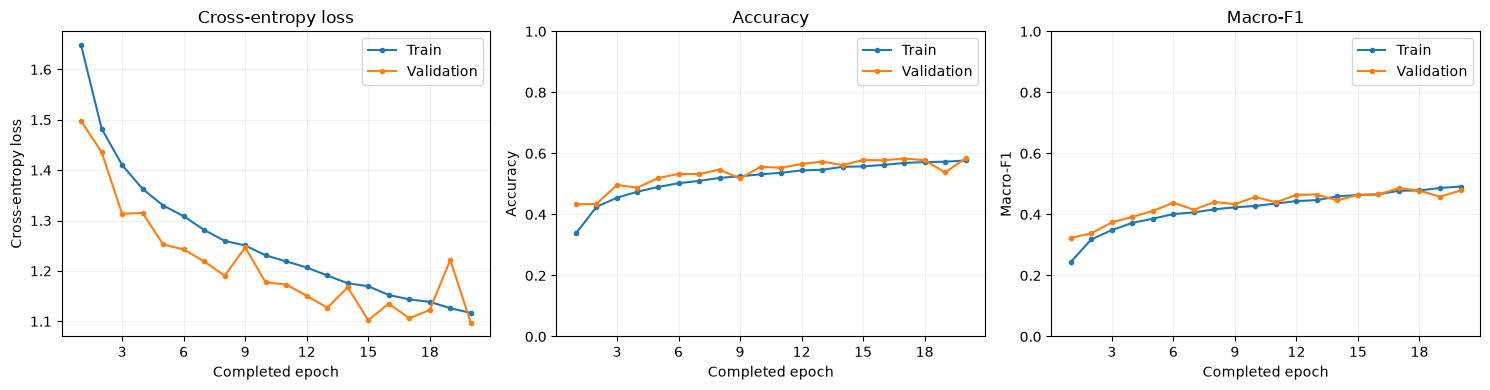

In [26]:
history = read_csv('history.csv')
if history is not None and 'epoch' in history:
    history['epoch'] = pd.to_numeric(history['epoch'], errors='coerce')
    required = ['epoch'] + [column for column in ['val_accuracy', 'val_macro_f1']
                            if column in history]
    history = history.dropna(subset=required).sort_values('epoch').copy()
if history is None or history.empty or 'epoch' not in history:
    print('Pending: history.csv with at least one completed epoch.')
else:
    table = history.copy()
    for column in list(table.columns):
        if 'accuracy' in column or 'macro_f1' in column:
            table[column] = pd.to_numeric(table[column], errors='coerce') * 100
            table = table.rename(columns={column: column + '_percent'})
    display(table.round(4))
    selection = 'val_accuracy' if EXPECTED_TASK == 'face' else 'val_macro_f1'
    if selection in history:
        scores = pd.to_numeric(history[selection], errors='coerce')
        if scores.notna().any():
            best = history.loc[scores.idxmax()]
            print(f"Completed epochs: {int(history['epoch'].max())}")
            print(f"Best epoch by {selection}: {int(best['epoch'])}, score: {float(best[selection]):.2%}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for axis, metric, title in zip(axes, ['loss', 'accuracy', 'macro_f1'],
                                   ['Cross-entropy loss', 'Accuracy', 'Macro-F1']):
        plotted = False
        for split, label in [('train', 'Train'), ('val', 'Validation')]:
            column = f'{split}_{metric}'
            if column in history:
                axis.plot(history['epoch'], history[column], marker='o', markersize=3, label=label)
                plotted = True
        axis.set(xlabel='Completed epoch', ylabel=title, title=title)
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        if metric != 'loss':
            axis.set_ylim(0, 1)
        if plotted:
            axis.legend()
        axis.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## 4. Saved classification evaluation
These values come from the saved evaluation JSON. They are not calculated from training
accuracy. The recorded `split` tells you whether the evaluation used validation or test.
Continuing training can change `best.pt`, so the checkpoint check identifies older results.

In [27]:
classification = read_json('classification/classification_metrics.json')
if classification is None:
    print('Pending: classification/classification_metrics.json. Run evaluation in Terminal first.')
else:
    check_evaluation_identity(classification, 'Classification evaluation')
    print('Task:', classification.get('task'), '| Split:', classification.get('split'),
          '| Samples:', classification.get('samples'))
    rows = [{'Metric': key, 'Percent': float(classification[key]) * 100}
            for key in ['accuracy', 'balanced_accuracy', 'macro_f1'] if key in classification]
    display(pd.DataFrame(rows).round(3))

Classification evaluation: checkpoint matches current best.pt.
Task: emotion | Split: test | Samples: 7178


,Metric,Percent
0,accuracy,58.512
1,balanced_accuracy,49.286
2,macro_f1,49.030


## 5. Saved per-class report
Precision, recall, F1, and support come from the report saved by evaluation.
The label order is taken from the actual model configuration when available.

In [28]:
report = read_json('classification/classification_report.json')
if report is None:
    print('Pending: classification/classification_report.json')
else:
    rows = []
    labels = config.get('classes') or [key for key, value in report.items()
                                      if isinstance(value, dict)
                                      and key not in ['macro avg', 'weighted avg', 'micro avg']]
    for label in labels:
        if isinstance(report.get(label), dict):
            values = report[label]
            rows.append({'Class': label, 'Precision_percent': values.get('precision', 0) * 100,
                         'Recall_percent': values.get('recall', 0) * 100,
                         'F1_percent': values.get('f1-score', 0) * 100,
                         'Support': values.get('support')})
    display(pd.DataFrame(rows).round(3))

,Class,Precision_percent,Recall_percent,F1_percent,Support
0,angry,50.338,46.660,48.429,958.0
1,disgust,80.000,3.604,6.897,111.0
2,fear,41.815,22.949,29.634,1024.0
3,happy,81.747,82.300,82.022,1774.0
4,neutral,51.646,61.071,55.964,1233.0
5,sad,42.901,56.215,48.664,1247.0
6,surprise,71.006,72.202,71.599,831.0


## 6. Saved confusion matrix
This displays the existing image from evaluation. Rows are true labels and columns are
predicted labels. No model or dataset is loaded to display the image.

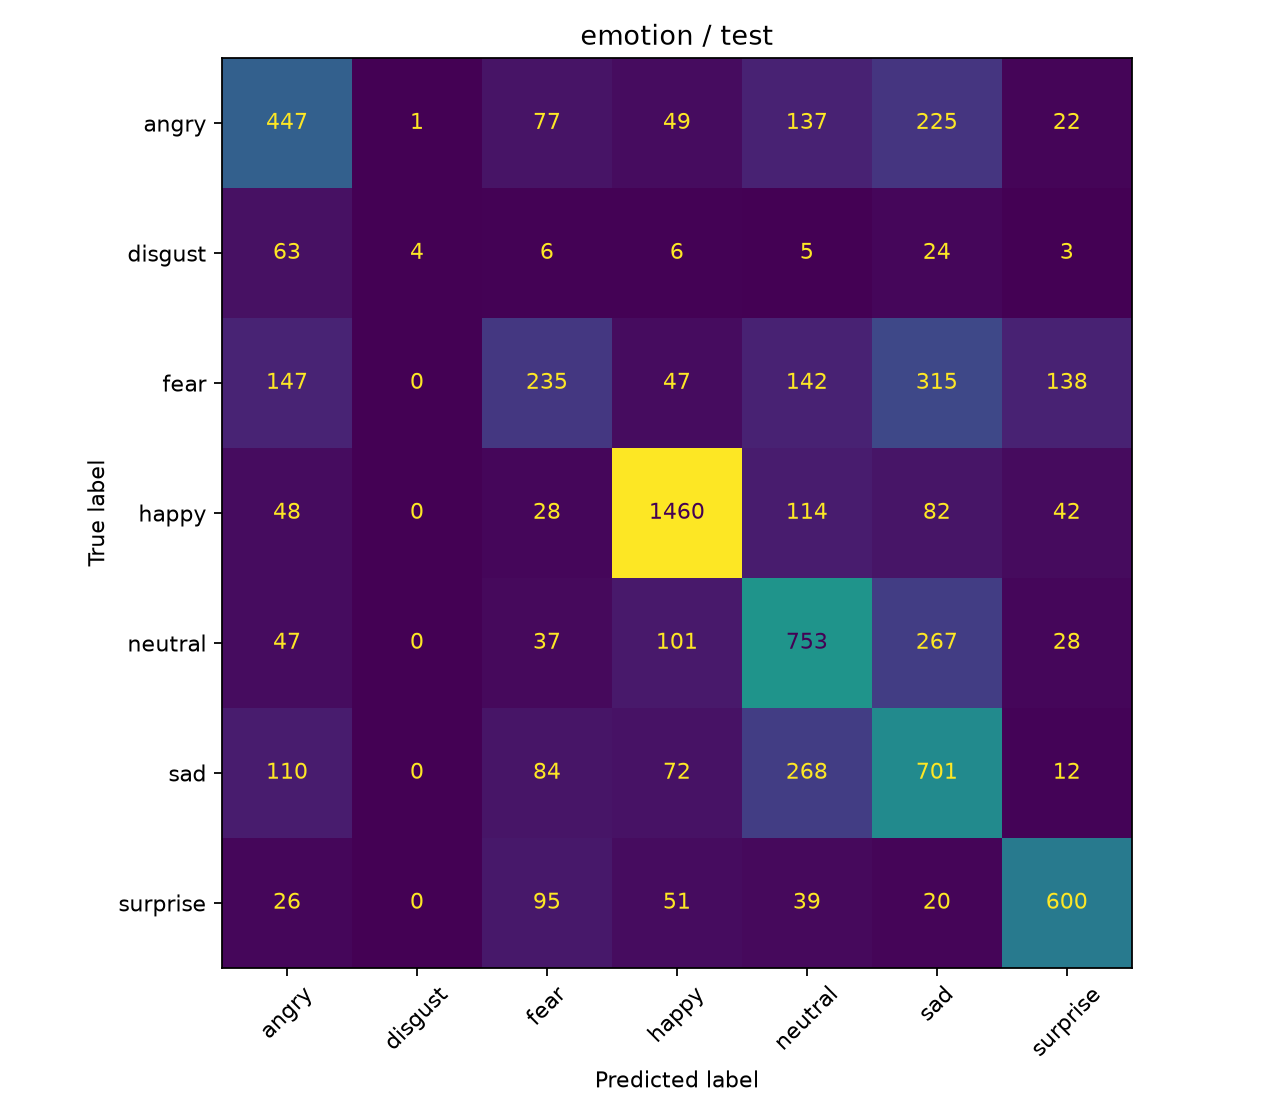

In [29]:
show_image('classification/confusion_matrix.png')

## 7. Discussion to complete after the experiment
- Report accuracy, balanced accuracy, macro-F1, and the dataset split.
- Identify commonly confused expression classes using the per-class report and confusion matrix.
- Discuss class imbalance, possible label noise, and generalization to webcam conditions.
- State the actual source/version and whether duplicates or subject overlap were checked.
- Keep test results separate from the validation metrics used to choose the checkpoint.